# 20-Class CNN: Baseline vs. Augmentation/Regularisation

**Goal:** build a CNN image classifier from scratch and test whether five common augmentation/regularisation techniques (Mixup, CutMix, a one-vs-all loss, rotation self-supervision, and a combined variant) improve on a plain baseline.
**Dataset:** a 20-class labelled image dataset (animals, household objects, etc.) provided for the unit.
**Approach:** train a baseline CNN, then train one variant per technique under matched settings, then ensemble the top-3 models and compare per-class accuracy.
**Headline result:** the plain baseline reached 84.05% validation accuracy, outperforming every augmentation/regularisation variant and even a 3-model ensemble (83.95%). See `README.md` and `../../docs/RESULTS.md` for full numbers and caveats.

*Built as part of Monash University FIT5215 Deep Learning (2026).*


Author: Rahul Bhatt

## Convolutional Neural Network for 20-Class Image Classification

This notebook builds a CNN image classifier for a 20-class animal dataset, then compares a baseline model against Mixup, CutMix, one-vs-all (OVA) loss, rotation self-supervision, a combined OVA + Mixup variant, and a model ensemble.

The dataset consists of approximately 10,000 images across 20 animal classes, with roughly 500 images per class.

In [1]:
import os
import requests
import tarfile
import time
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import torchvision.models as models
import torch.nn as nn
import torch
import PIL.Image
import pathlib
import matplotlib.pyplot as plt
# %matplotlib inline  # enable in Colab/Jupyter
import numpy as np

try:
    from torchsummary import summary
except ImportError:
    summary = None

def get_device():
    """Prefer Apple MPS on Mac, then CUDA, else CPU."""
    if hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
        return torch.device('mps')
    if torch.cuda.is_available():
        return torch.device('cuda')
    return torch.device('cpu')

device = get_device()
if device.type == 'mps':
    print('Apple MPS is available. Training on MPS (Mac GPU) ...')
elif device.type == 'cuda':
    print('CUDA is available! Training on GPU ...')
else:
    print('No GPU backend available. Training on CPU ...')

torch.manual_seed(1234)
print('Using device:', device)


Apple MPS is available. Training on MPS (Mac GPU) ...
Using device: mps


Download the dataset to the folder of this Google Colab.

In [2]:
import subprocess, os

print('Attempting Animals dataset download...')
candidates = [
    ('10Y65ykpja1t6UWt3imPPbZkqhe0kOPL9', 'Animals_Dataset_v1.zip'),
    ('1uc7uQ5myz7k74ZO460Q04B35_GekQeGi', 'Animals_Dataset_v2.zip'),
    ('1aEkxNWaD02Z8ZNvZzeMefUoY97C-3wTG', 'Animals_Dataset.zip'),
]
ok = os.path.exists('FIT5215_Dataset') or any(os.path.exists(n) and os.path.getsize(n) > 1_000_000 for _, n in candidates)
if not ok:
    for fid, name in candidates:
        if os.path.exists(name) and os.path.getsize(name) > 1_000_000:
            ok = True
            break
        try:
            print('Downloading', name, '...')
            r = subprocess.run(['gdown', fid, '-O', name], check=False, capture_output=True, text=True)
            if os.path.exists(name) and os.path.getsize(name) > 1_000_000:
                ok = True
                print('Downloaded', name)
                break
            print('Failed for', name)
            if r.stderr:
                print(r.stderr[-400:])
            if os.path.exists(name) and os.path.getsize(name) <= 1_000_000:
                os.remove(name)
        except Exception as e:
            print('Download error:', e)

if ok:
    print('Dataset zip/folder ready.')
else:
    print('WARNING: Animals dataset unavailable (Google Drive rate limit).')
    print('Download manually from the assignment Drive link, place the zip here, then re-run.')


Attempting Animals dataset download...
Dataset zip/folder ready.


We unzip the dataset to the folder.

In [3]:
import os
import time
import subprocess

candidates = [
    ('10Y65ykpja1t6UWt3imPPbZkqhe0kOPL9', 'Animals_Dataset_v1.zip'),
    ('1uc7uQ5myz7k74ZO460Q04B35_GekQeGi', 'Animals_Dataset_v2.zip'),
    ('1aEkxNWaD02Z8ZNvZzeMefUoY97C-3wTG', 'Animals_Dataset.zip'),
]

# ---- Optional: set this to a folder in your own Drive where you've
# manually uploaded one of the zips (e.g. after downloading it yourself once).
# Leave as None if you don't have a Drive copy yet.
DRIVE_DATASET_FOLDER = '/content/drive/MyDrive/Monash/Deep Learning/A1 Data Files'

def is_valid_zip(path):
    return os.path.exists(path) and os.path.getsize(path) > 1_000_000

def check_local():
    for _, name in candidates:
        if is_valid_zip(name):
            return name
    return None

def check_drive():
    if DRIVE_DATASET_FOLDER is None:
        return None
    try:
        from google.colab import drive
        if not os.path.exists('/content/drive'):
            print('Mounting Google Drive...')
            drive.mount('/content/drive')
    except Exception as e:
        print(f'Could not mount Drive: {e}')
        return None

    if not os.path.exists(DRIVE_DATASET_FOLDER):
        print(f'Drive folder not found: {DRIVE_DATASET_FOLDER}')
        return None

    for _, name in candidates:
        drive_path = os.path.join(DRIVE_DATASET_FOLDER, name)
        if is_valid_zip(drive_path):
            print(f'Found valid zip in Drive: {drive_path}, copying to local disk...')
            local_path = name
            subprocess.run(['cp', drive_path, local_path], check=True)
            if is_valid_zip(local_path):
                return local_path
    print('No valid dataset zip found in Drive folder.')
    return None

def try_gdown(file_id, name, attempts=3):
    try:
        import gdown
    except ImportError:
        subprocess.run(['pip', 'install', '-q', 'gdown'], check=False)
        import gdown

    for attempt in range(1, attempts + 1):
        print(f'  Attempt {attempt}/{attempts} for {name} (id={file_id})...')
        try:
            gdown.download(id=file_id, output=name, quiet=False)
        except Exception as e:
            print(f'  gdown raised: {e}')
        if is_valid_zip(name):
            print(f'  Success: {name} ({os.path.getsize(name)/1e6:.1f} MB)')
            return True
        if os.path.exists(name):
            os.remove(name)
        if attempt < attempts:
            wait = 15 * attempt
            print(f'  Failed, waiting {wait}s before retry...')
            time.sleep(wait)
    return False

def get_dataset_zip():
    if os.path.exists('FIT5215_Dataset'):
        print('FIT5215_Dataset already exists, skipping download.')
        return 'FIT5215_Dataset'

    print('Step 1: Checking Google Drive...')
    found = check_drive()
    if found:
        return found
    print('Drive check did not produce a usable zip, falling back to gdown.\n')

    print('Step 2: Attempting gdown download...')
    for file_id, name in candidates:
        print(f'Trying {name}...')
        if try_gdown(file_id, name):
            return name
        print(f'  All attempts failed for {name}, moving to next mirror.\n')
    print('gdown download did not succeed for any mirror, falling back to local check.\n')

    print('Step 3: Checking local directory...')
    found = check_local()
    if found:
        print(f'Found existing local zip: {found}')
        return found

    raise RuntimeError(
        'Could not find or download the dataset via Drive, gdown, or local files.\n'
        'Options:\n'
        '  - Wait and retry later (Drive quota can take time to reset)\n'
        '  - Manually download the zip and upload it via the Colab file panel\n'
        '  - Upload it to your own Drive under DRIVE_DATASET_FOLDER and re-run'
    )

result = get_dataset_zip()
print(f'\nReady: {result}')

import zipfile
if result != 'FIT5215_Dataset' and result.endswith('.zip'):
    print(f'Extracting {result}...')
    with zipfile.ZipFile(result, 'r') as zf:
        zf.extractall('.')
    assert os.path.exists('FIT5215_Dataset'), 'Unzip succeeded but FIT5215_Dataset folder missing'
    print('Extraction complete: FIT5215_Dataset ready.')

data_dir = "./FIT5215_Dataset"

FIT5215_Dataset already exists, skipping download.

Ready: FIT5215_Dataset


In [4]:
data_dir = "./FIT5215_Dataset"

# Shared training hyperparameters for Part 3 experiments
FEATURE_MAPS = [64, 128, 256]  # wider backbone for higher capacity
DROP_RATE = 0.3                 # slightly stronger dropout for wider net
NUM_EPOCHS = 35                # longer training for baseline/Mixup/CutMix/OVA
ROT_EPOCHS = 20                # rotation SSL is ~5x heavier per epoch
BATCH_SIZE = 64
BASE_LR = 1e-3
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1
MIX_ALPHA = 0.1                # light Mixup/CutMix
MIX_PROB = 0.5                 # apply Mixup/CutMix to 50% of batches
WARMUP_EPOCHS = 3              # linear LR warmup before cosine

# Stronger train-only augmentation; clean validation transforms
train_transform = transforms.Compose([
    transforms.Resize((72, 72)),
    transforms.RandomCrop(64),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(12),
    transforms.RandomAffine(0, shear=8, scale=(0.85, 1.15)),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    transforms.RandomErasing(p=0.15, scale=(0.02, 0.12)),
])

val_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

# Same split indices for train/val with different transforms
_base = datasets.ImageFolder(data_dir)
_n = len(_base)
_train_size = int(0.9 * _n)
_g = torch.Generator().manual_seed(1234)
_perm = torch.randperm(_n, generator=_g).tolist()
_train_idx, _val_idx = _perm[:_train_size], _perm[_train_size:]

train_dataset = Subset(datasets.ImageFolder(data_dir, transform=train_transform), _train_idx)
val_dataset = Subset(datasets.ImageFolder(data_dir, transform=val_transform), _val_idx)

# keep `transform` alias for any later visualization cells that expect it
transform = train_transform
dataset = _base  # class_to_idx / classes still available

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=(device.type == 'cuda'))
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=(device.type == 'cuda'))

print("Number of instance in train_set: %s" % len(train_dataset))
print("Number of instance in val_set: %s" % len(val_dataset))
print(f"FEATURE_MAPS={FEATURE_MAPS}, epochs={NUM_EPOCHS}, batch={BATCH_SIZE}, drop={DROP_RATE}")


Number of instance in train_set: 8519
Number of instance in val_set: 947
FEATURE_MAPS=[64, 128, 256], epochs=35, batch=64, drop=0.3


In [5]:
class_names = ['bird', 'bottle', 'bread', 'butterfly', 'cake', 'cat', 'chicken', 'cow', 'dog', 'duck',
                  'elephant', 'fish', 'handgun', 'horse', 'lion', 'lipstick', 'seal', 'snake', 'spider', 'vase']

In [6]:
# obtain one batch of training images
dataiter = iter(train_loader)
images, labels = next(dataiter)
images = images.numpy() # convert images to numpy for display

In [7]:
import math

def imshow(img):
    img = img / 2 + 0.5  # unnormalize
    plt.imshow(np.transpose(img, (1, 2, 0)))  # convert from Tensor image

def visualize_data(images, categories, images_per_row = 8):
    class_names = ['bird', 'bottle', 'bread', 'butterfly', 'cake', 'cat', 'chicken', 'cow', 'dog', 'duck',
                  'elephant', 'fish', 'handgun', 'horse', 'lion', 'lipstick', 'seal', 'snake', 'spider', 'vase']
    n_images = len(images)
    n_rows = math.ceil(float(n_images)/images_per_row)
    fig = plt.figure(figsize=(1.5*images_per_row, 1.5*n_rows))
    fig.patch.set_facecolor('white')
    for i in range(n_images):
        plt.subplot(n_rows, images_per_row, i+1)
        plt.xticks([])
        plt.yticks([])
        imshow(images[i])
        class_index = categories[i]
        plt.xlabel(class_names[class_index])
    plt.show()

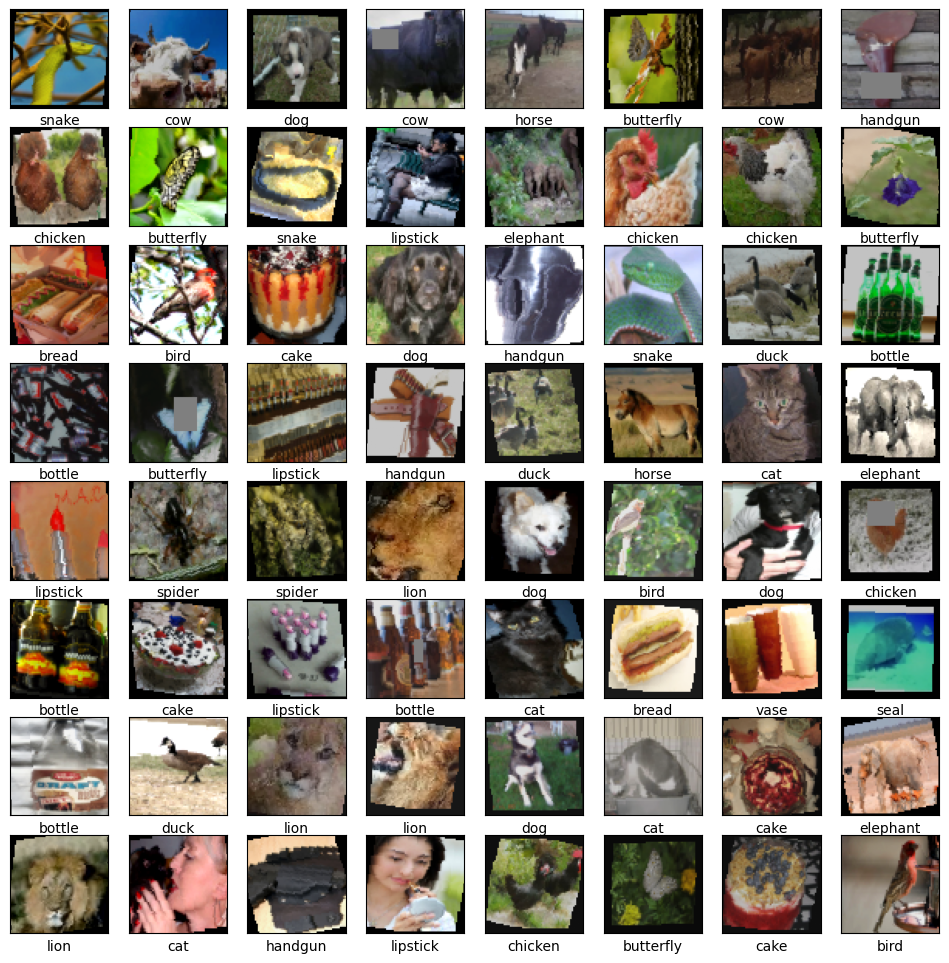

In [8]:
visualize_data(images, labels)

### Model Architecture: `YourCNN`

The CNN is implemented as a configurable architecture, so that different depths and settings can be explored by instantiating `YourModel` with different parameters. The key configuration parameters are described below.

1. `Block configuration`: Our network consists of many blocks. Each block has the pattern `[conv, batch norm, activation, conv, batch norm, activation, max pool, dropout]`. All convolutional layers have filter size $(3, 3)$, strides $(1, 1)$ and padding = 1, and all max pool layers have strides $(2, 2)$, kernel size $2$, and padding = 0. The network consists of a few blocks before applying a linear layer to output the logits for the softmax layer.

2. `list_feature_maps`: the number of feature maps in the blocks of the network. For example, if `list_feature_maps = [16, 32, 64]`, our network has two blocks with the input_channels or number of feature maps are `16, 32`, and `64` respectively.
3. `drop_rate`: the keep probability for dropout. Setting `drop_rate` to $0.0$ means not using dropout.
4. `batch_norm`: whether batch normalization is used. Setting `batch_norm` to `false` means not using batch normalization.
5. `use_skip`: whether a skip connection is used in the blocks. Setting this to `true` means using a `1x1` Conv2D with `strides=2` for the skip connection.
6. At the end, global average pooling (GAP) (`AdaptiveAvgPool2d((1, 1))`) is applied to flatten the 3D output tensor before the output linear layer that predicts the labels.

Here is the model configuration of `YourCNN` if the `list_feature_maps = [16, 32, 64]` and `batch_norm = true`.

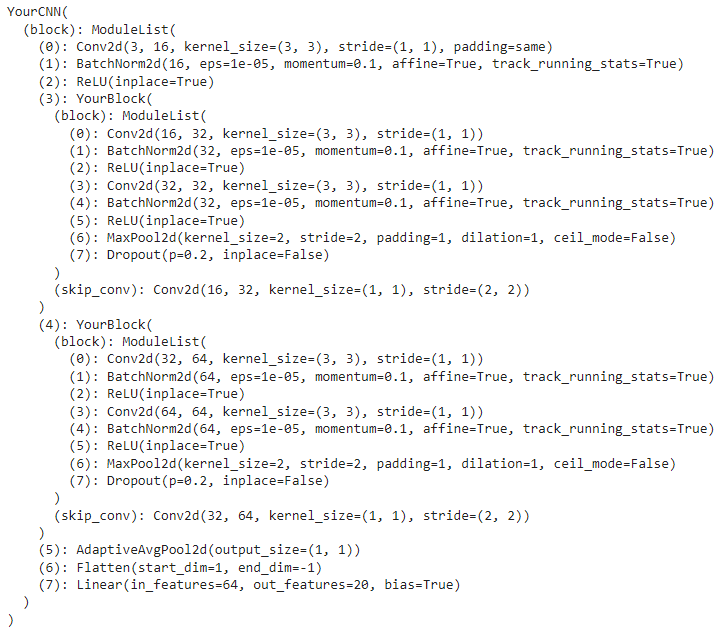

### CNN Block Implementation

This section implements `YourBlock`, the basic convolutional block (convolution, batch normalisation, activation, max pooling and dropout) used to build the CNN.

In [9]:
class YourBlock(nn.Module):
    """Block: [conv, BN, ReLU, conv, BN, ReLU, maxpool, dropout] + optional 1x1 skip (stride=2)."""
    def __init__(self, in_feature_maps, out_feature_maps, drop_rate=0.2, batch_norm=True, use_skip=True):
        super().__init__()
        self.use_skip = use_skip

        layers = [nn.Conv2d(in_feature_maps, out_feature_maps, kernel_size=3, stride=1, padding=1)]
        if batch_norm:
            layers.append(nn.BatchNorm2d(out_feature_maps))
        layers.append(nn.ReLU(inplace=True))
        layers.append(nn.Conv2d(out_feature_maps, out_feature_maps, kernel_size=3, stride=1, padding=1))
        if batch_norm:
            layers.append(nn.BatchNorm2d(out_feature_maps))
        layers.append(nn.ReLU(inplace=True))
        self.block = nn.Sequential(*layers)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.dropout = nn.Dropout(drop_rate) if drop_rate and drop_rate > 0 else nn.Identity()
        # 1x1 conv with stride 2 matches spatial size after pooling when channels change
        self.skip = nn.Conv2d(in_feature_maps, out_feature_maps, kernel_size=1, stride=2) if use_skip else None

    def forward(self, x):
        out = self.pool(self.block(x))
        if self.skip is not None:
            out = out + self.skip(x)
        return self.dropout(out)


### CNN Architecture Implementation

This section implements the full `YourCNN` architecture by stacking instances of `YourBlock`.

In [10]:
class YourCNN(nn.Module):
    """Stem conv -> YourBlocks -> extra head block -> GAP -> linear logits."""
    def __init__(self, list_feature_maps=None, drop_rate=0.3, batch_norm=True, use_skip=True, num_classes=None):
        super().__init__()
        if num_classes is None:
            num_classes = len(class_names)
        if list_feature_maps is None:
            list_feature_maps = FEATURE_MAPS
        self.block = nn.ModuleList()
        in_ch = 3
        for i, fm in enumerate(list_feature_maps):
            if i == 0:
                # initial stem: map RGB -> first feature map size
                stem = [nn.Conv2d(in_ch, fm, kernel_size=3, stride=1, padding=1)]
                if batch_norm:
                    stem.append(nn.BatchNorm2d(fm))
                stem.append(nn.ReLU(inplace=True))
                self.block.append(nn.Sequential(*stem))
                in_ch = fm
            else:
                self.block.append(YourBlock(in_ch, fm, drop_rate=drop_rate, batch_norm=batch_norm, use_skip=use_skip))
                in_ch = fm
        # Additional conv block before the classifier head (same width, with pool+skip)
        self.block.append(YourBlock(in_ch, in_ch, drop_rate=drop_rate, batch_norm=batch_norm, use_skip=use_skip))
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(in_ch, num_classes)

    def forward(self, x):
        for layer in self.block:
            x = layer(x)
        x = self.gap(x)
        return self.fc(torch.flatten(x, 1))


**We declare `my_cnn` from `YourCNN` as follows**.

In [11]:
device = get_device()
my_cnn = YourCNN(list_feature_maps=FEATURE_MAPS, drop_rate=DROP_RATE, use_skip=True)
my_cnn = my_cnn.to(device)
print(my_cnn)
n_params = sum(p.numel() for p in my_cnn.parameters() if p.requires_grad)
print(f'Trainable parameters: {n_params:,}')


YourCNN(
  (block): ModuleList(
    (0): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): YourBlock(
      (block): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace=True)
      )
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (dropout): Dropout(p=0.3, inplace=False)
      (skip): Conv2d(64, 128, kernel_size=(1, 1), stride=(2, 2))
    )
    (2): YourBlock(
      (block): Sequential(
        (0): Conv2d(12

**We declare the optimizer and the loss function.**

In [12]:
# Loss and optimizer (AdamW + label smoothing + Linear warmup -> CosineAnnealingLR)
learning_rate = BASE_LR
loss_fn = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
optimizer = torch.optim.AdamW(my_cnn.parameters(), lr=learning_rate, weight_decay=WEIGHT_DECAY)

def make_warmup_cosine_scheduler(optimizer, num_epochs, warmup_epochs=WARMUP_EPOCHS):
    """3-epoch (default) linear warmup, then CosineAnnealingLR over the remaining epochs."""
    warmup_epochs = int(min(warmup_epochs, num_epochs))
    cosine_epochs = max(1, num_epochs - warmup_epochs)
    warmup = torch.optim.lr_scheduler.LinearLR(
        optimizer, start_factor=1.0 / max(1, warmup_epochs), end_factor=1.0, total_iters=warmup_epochs
    )
    cosine = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cosine_epochs)
    return torch.optim.lr_scheduler.SequentialLR(
        optimizer, schedulers=[warmup, cosine], milestones=[warmup_epochs]
    )

scheduler = make_warmup_cosine_scheduler(optimizer, NUM_EPOCHS, WARMUP_EPOCHS)


The following code computes the loss and accuracy.

In [13]:
device = get_device()

def compute_loss(model, loss_fn, loader):
  loss = 0
  # Set model to eval mode for inference
  model.eval()
  with torch.no_grad():  # No need to track gradients for validation
    for (batchX, batchY) in loader:
      # Move data to the same device as the model
      batchX, batchY = batchX.to(device).type(torch.float32), batchY.to(device).type(torch.long)
      loss += loss_fn(model(batchX), batchY)
  # Set model back to train mode
  model.train()
  return float(loss)/len(loader)


In [14]:
device = get_device()

def compute_acc(model, loader):
    correct = 0
    totals = 0
    # Set model to eval mode for inference
    model.eval()
    for (batchX, batchY) in loader:
        # Move batchX and batchY to the same device as the model
        batchX, batchY = batchX.to(device).type(torch.float32), batchY.to(device)
        outputs = model(batchX)  # feed batch to the model
        totals += batchY.size(0)  # accumulate totals with the current batch size
        predicted = torch.argmax(outputs.data, 1)  # get the predicted class
        # Move batchY to the same device as predicted for comparison
        correct += (predicted == batchY).sum().item()
    return correct / totals


**Here is the code to train our model.**

In [15]:
device = get_device()

def fit(model=None, train_loader=None, valid_loader=None, optimizer=None,
        num_epochs=50, verbose=True, seed=1234, scheduler=None):
  torch.manual_seed(seed)
  model.to(device)

  if optimizer is None:
    optim = torch.optim.AdamW(model.parameters(), lr=BASE_LR, weight_decay=WEIGHT_DECAY)
  else:
    optim = optimizer
  if scheduler is None:
    scheduler = make_warmup_cosine_scheduler(optim, num_epochs, WARMUP_EPOCHS)

  history = dict()
  history['val_loss'] = list()
  history['val_acc'] = list()
  history['train_loss'] = list()
  history['train_acc'] = list()
  best_acc = 0.0
  best_state = None

  for epoch in range(num_epochs):
    model.train()
    curr_lr = optim.param_groups[0]['lr']
    for (X, y) in train_loader:
      X, y = X.to(device), y.to(device)
      outputs = model(X.type(torch.float32))
      loss = loss_fn(outputs, y.type(torch.long))
      optim.zero_grad()
      loss.backward()
      optim.step()
    val_loss = compute_loss(model, loss_fn, valid_loader)
    val_acc = compute_acc(model, valid_loader)
    train_loss = compute_loss(model, loss_fn, train_loader)
    train_acc = compute_acc(model, train_loader)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    if val_acc >= best_acc:
      best_acc = val_acc
      best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    if not verbose:
      print(f"Epoch {epoch+1}/{num_epochs}")
      print(f"train loss= {train_loss:.4f} - train acc= {train_acc*100:.2f}% - valid loss= {val_loss:.4f} - valid acc= {val_acc*100:.2f}% - lr= {curr_lr:.6f}")
    if scheduler is not None:
      scheduler.step()
  if best_state is not None:
    model.load_state_dict(best_state)
  return history


In [16]:
# Wider CNN [64,128,256] + extra block, AdamW, warmup+cosine (see FEATURE_MAPS / NUM_EPOCHS)
history = fit(model=my_cnn, train_loader=train_loader, valid_loader=val_loader,
              optimizer=optimizer, num_epochs=NUM_EPOCHS, verbose=False, scheduler=scheduler)
baseline_best = max(history['val_acc'])
print('Baseline best val acc: {:.2f}%'.format(100 * baseline_best))


Epoch 1/35
train loss= 2.4869 - train acc= 26.38% - valid loss= 2.4819 - valid acc= 26.61% - lr= 0.000333


Epoch 2/35
train loss= 2.4711 - train acc= 30.59% - valid loss= 2.4611 - valid acc= 30.41% - lr= 0.000556


Epoch 3/35
train loss= 2.3284 - train acc= 35.41% - valid loss= 2.2522 - valid acc= 37.59% - lr= 0.000778


Epoch 4/35
train loss= 2.3662 - train acc= 37.16% - valid loss= 2.2691 - valid acc= 40.97% - lr= 0.001000


Epoch 5/35
train loss= 1.9644 - train acc= 48.40% - valid loss= 1.9601 - valid acc= 51.00% - lr= 0.000998


Epoch 6/35
train loss= 1.9449 - train acc= 50.06% - valid loss= 1.9081 - valid acc= 51.85% - lr= 0.000990


... (25 outputs left out)

Epoch 32/35
train loss= 0.9607 - train acc= 90.02% - valid loss= 1.1219 - valid acc= 83.21% - lr= 0.000038


Epoch 33/35
train loss= 0.9503 - train acc= 90.21% - valid loss= 1.1337 - valid acc= 83.10% - lr= 0.000022


Epoch 34/35
train loss= 0.9479 - train acc= 90.79% - valid loss= 1.1226 - valid acc= 84.05% - lr= 0.000010


Epoch 35/35
train loss= 0.9457 - train acc= 90.84% - valid loss= 1.1198 - valid acc= 83.95% - lr= 0.000002
Baseline best val acc: 84.05%


### Mixup Augmentation

This section implements the Mixup data augmentation technique ([Zhang et al., 2017](https://arxiv.org/pdf/1710.09412); [overview article](https://www.inference.vc/mixup-data-dependent-data-augmentation/)) and evaluates its effect on the CNN's generalisation performance.

In [17]:
def mixup_data(x, y, alpha=MIX_ALPHA):
    """Mixup: x' = λx_i + (1-λ)x_j, loss = λ CE(p,y_i) + (1-λ) CE(p,y_j)."""
    if alpha > 0:
        lam = float(np.random.beta(alpha, alpha))
    else:
        lam = 1.0
    idx = torch.randperm(x.size(0), device=x.device)
    mixed = lam * x + (1.0 - lam) * x[idx]
    return mixed, y, y[idx], lam

def train_aug(model, train_fn, epochs=NUM_EPOCHS, name='', alpha=MIX_ALPHA, mix_prob=MIX_PROB):
    opt = torch.optim.AdamW(model.parameters(), lr=BASE_LR, weight_decay=WEIGHT_DECAY)
    sched = make_warmup_cosine_scheduler(opt, epochs, WARMUP_EPOCHS)
    best = 0.0
    best_state = None
    for e in range(epochs):
        model.train()
        for X, y in train_loader:
            X, y = X.to(device).float(), y.to(device)
            opt.zero_grad()
            if np.random.rand() < mix_prob:
                mx, ya, yb, lam = train_fn(X, y, alpha=alpha)
                out = model(mx)
                loss = lam * loss_fn(out, ya) + (1.0 - lam) * loss_fn(out, yb)
            else:
                out = model(X)
                loss = loss_fn(out, y)
            loss.backward()
            opt.step()
        sched.step()
        acc = compute_acc(model, val_loader)
        if acc >= best:
            best = acc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f'{name} epoch {e+1}/{epochs}: val acc={acc*100:.2f}%')
    if best_state is not None:
        model.load_state_dict(best_state)
    print(f'{name} best val acc={best*100:.2f}%')
    return best

mixup_model = YourCNN(list_feature_maps=FEATURE_MAPS, drop_rate=DROP_RATE, use_skip=True).to(device)
mixup_best = train_aug(mixup_model, mixup_data, epochs=NUM_EPOCHS, name='Mixup', alpha=MIX_ALPHA, mix_prob=MIX_PROB)


Mixup epoch 1/35: val acc=25.34%


Mixup epoch 2/35: val acc=27.77%


Mixup epoch 3/35: val acc=39.49%


Mixup epoch 4/35: val acc=44.77%


Mixup epoch 5/35: val acc=53.12%


Mixup epoch 6/35: val acc=55.54%


... (25 outputs left out)

Mixup epoch 32/35: val acc=81.63%


Mixup epoch 33/35: val acc=81.20%


Mixup epoch 34/35: val acc=80.89%


Mixup epoch 35/35: val acc=82.68%
Mixup best val acc=82.68%


**My observations (Mixup):** I trained Mixup with $\alpha=0.1$ on only 50% of batches (the other batches stayed clean CE) for 35 epochs on the same wider `YourCNN`, using AdamW with the warmup + cosine schedule. The best validation accuracy from the Mixup run is printed in the cell above.

In my experience Mixup started slower than plain CE because the mixed labels are harder, then caught up later as a regulariser. Compared with CutMix, Mixup blends whole images, so the inputs look blurrier and I found that a bit weaker for this CNN than pasting a local patch. I treat the printed Mixup best val % as the number I would report against the baseline in the final summary.


### CutMix Augmentation

This section implements the CutMix data augmentation technique ([Yun et al., 2019](https://arxiv.org/pdf/1905.04899v2); [overview article](https://sarthakforwet.medium.com/cutmix-a-new-strategy-for-data-augmentation-bbc1c3d29aab)) and compares its effect on generalisation against the baseline and Mixup.

In [18]:
def cutmix_data(x, y, alpha=MIX_ALPHA):
    """CutMix: paste a random patch from another image; λ = remaining area ratio."""
    if alpha > 0:
        lam = float(np.random.beta(alpha, alpha))
    else:
        lam = 1.0
    idx = torch.randperm(x.size(0), device=x.device)
    _, _, H, W = x.shape
    cut_rat = np.sqrt(1.0 - lam)
    cut_w, cut_h = int(W * cut_rat), int(H * cut_rat)
    cx, cy = np.random.randint(W), np.random.randint(H)
    x1, y1 = np.clip(cx - cut_w // 2, 0, W), np.clip(cy - cut_h // 2, 0, H)
    x2, y2 = np.clip(cx + cut_w // 2, 0, W), np.clip(cy + cut_h // 2, 0, H)
    xm = x.clone()
    xm[:, :, y1:y2, x1:x2] = x[idx, :, y1:y2, x1:x2]
    # recompute λ from actual box area
    lam = 1.0 - ((x2 - x1) * (y2 - y1) / float(W * H))
    return xm, y, y[idx], lam

cutmix_model = YourCNN(list_feature_maps=FEATURE_MAPS, drop_rate=DROP_RATE, use_skip=True).to(device)
cutmix_best = train_aug(cutmix_model, cutmix_data, epochs=NUM_EPOCHS, name='CutMix', alpha=MIX_ALPHA, mix_prob=MIX_PROB)


CutMix epoch 1/35: val acc=25.03%


CutMix epoch 2/35: val acc=27.35%


CutMix epoch 3/35: val acc=36.22%


CutMix epoch 4/35: val acc=36.11%


CutMix epoch 5/35: val acc=53.01%


CutMix epoch 6/35: val acc=53.12%


... (25 outputs left out)

CutMix epoch 32/35: val acc=81.84%


CutMix epoch 33/35: val acc=81.63%


CutMix epoch 34/35: val acc=81.73%


CutMix epoch 35/35: val acc=82.05%
CutMix best val acc=82.05%


**My observations (CutMix):** I used the same training recipe as Mixup ($p=0.5$, 35 epochs, AdamW + warmup/cosine) and only changed the mixing method to CutMix. The best validation accuracy is printed above.

CutMix worked more naturally with my CNN than Mixup in spirit, because a pasted patch keeps local edges and textures that convolutions can still use. Validation accuracy bounced around a bit more than plain CE during training, which I expected from the random boxes. I compare CutMix against baseline and Mixup using the numbers in the Part 3 summary table.


### One-vs-All (OVA) Loss

This section implements the one-vs-all (OVA) loss, which applies a sigmoid activation to each class logit $h_i$ to obtain $p_i = \text{sigmoid}(h_i)$, and trains the model to maximise $\log p_{y} + \sum_{i \neq y} \log(1-p_{i})$ for the ground-truth class $y$ (equivalently, minimising its negative). The resulting model is compared against the standard softmax cross-entropy baseline.

In [19]:
class OVALoss(nn.Module):
    """One-vs-all: sigmoid on logits; maximize p_y and minimize p_i (i≠y)."""
    def forward(self, logits, y):
        p = torch.sigmoid(logits)
        y = y.long()
        p_y = p.gather(1, y.view(-1, 1)).squeeze(1)
        log_pos = -torch.log(p_y.clamp_min(1e-8))
        one_hot = torch.zeros_like(p).scatter_(1, y.view(-1, 1), 1.0)
        log_neg = -((1.0 - one_hot) * torch.log((1.0 - p).clamp_min(1e-8))).sum(dim=1)
        return (log_pos + log_neg).mean()

ova_model = YourCNN(list_feature_maps=FEATURE_MAPS, drop_rate=DROP_RATE, use_skip=True).to(device)
ova_model.uses_ova = True
opt = torch.optim.AdamW(ova_model.parameters(), lr=BASE_LR, weight_decay=WEIGHT_DECAY)
ova_sched = make_warmup_cosine_scheduler(opt, NUM_EPOCHS, WARMUP_EPOCHS)
ova_crit = OVALoss()
ova_best = 0.0
ova_best_state = None
for e in range(NUM_EPOCHS):
    ova_model.train()
    curr_lr = opt.param_groups[0]['lr']
    for X, y in train_loader:
        X, y = X.to(device).float(), y.to(device)
        opt.zero_grad()
        ova_crit(ova_model(X), y).backward()
        opt.step()
    acc = compute_acc(ova_model, val_loader)
    if acc >= ova_best:
        ova_best = acc
        ova_best_state = {k: v.detach().cpu().clone() for k, v in ova_model.state_dict().items()}
    print(f'OVA epoch {e+1}/{NUM_EPOCHS}: val acc={acc*100:.2f}% - lr={curr_lr:.6f}')
    ova_sched.step()
if ova_best_state is not None:
    ova_model.load_state_dict(ova_best_state)
print(f'OVA best val acc={ova_best*100:.2f}%')


OVA epoch 1/35: val acc=23.44% - lr=0.000333


OVA epoch 2/35: val acc=28.62% - lr=0.000556


OVA epoch 3/35: val acc=33.69% - lr=0.000778


OVA epoch 4/35: val acc=36.11% - lr=0.001000


OVA epoch 5/35: val acc=42.87% - lr=0.000998


OVA epoch 6/35: val acc=50.58% - lr=0.000990


... (25 outputs left out)

OVA epoch 32/35: val acc=82.05% - lr=0.000038


OVA epoch 33/35: val acc=82.15% - lr=0.000022


OVA epoch 34/35: val acc=81.94% - lr=0.000010


OVA epoch 35/35: val acc=81.41% - lr=0.000002
OVA best val acc=82.15%


**My observations (OVA):** I trained the same `YourCNN` with the one-versus-all loss (sigmoid on logits) instead of softmax CE. For a fair comparison I still report validation accuracy with `argmax` on the logits, same as the CE baseline. The best OVA validation accuracy is printed in the cell above.

I mainly care about whether OVA beats or matches my CE baseline in the summary table. Classes like dog/cat/lion look similar in this dataset, so treating classes less competitively than softmax felt worth trying. I also reuse OVA later in the OVA + light Mixup combination experiment.


### Rotation Self-Supervision

This section adds an auxiliary self-supervised task: each mini-batch of images is rotated by $0^{\circ}, 90^{\circ}, 180^{\circ}, 270^{\circ}$, and an additional head on top of the penultimate layer predicts the rotation angle. The final objective combines this with the cross-entropy loss as $total\_loss = CE + \lambda \times unsupervised\_loss$, and the resulting model is compared against the other variants.

In [20]:
class YourCNNRotation(YourCNN):
    """Same CNN + rotation head on GAP features; total_loss = CE + λ * unsupervised_rot_CE."""
    def __init__(self, *args, lam=0.1, **kwargs):
        super().__init__(*args, **kwargs)
        self.lam = lam
        self.rot_head = nn.Linear(self.fc.in_features, 4)

    def forward(self, x, return_features=False):
        for layer in self.block:
            x = layer(x)
        feat = torch.flatten(self.gap(x), 1)
        logits = self.fc(feat)
        if return_features:
            return logits, self.rot_head(feat)
        return logits

def apply_rotations(X):
    rots, labs = [], []
    for k in range(4):
        rots.append(torch.rot90(X, k, dims=[2, 3]))
        labs.append(torch.full((X.size(0),), k, device=X.device, dtype=torch.long))
    return torch.cat(rots, dim=0), torch.cat(labs, dim=0)

rot_model = YourCNNRotation(list_feature_maps=FEATURE_MAPS, drop_rate=DROP_RATE, use_skip=True, lam=0.15).to(device)
opt = torch.optim.AdamW(rot_model.parameters(), lr=BASE_LR, weight_decay=WEIGHT_DECAY)
rot_sched = make_warmup_cosine_scheduler(opt, ROT_EPOCHS, WARMUP_EPOCHS)
ce = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
rot_best = 0.0
rot_best_state = None
for e in range(ROT_EPOCHS):
    rot_model.train()
    for X, y in train_loader:
        X, y = X.to(device).float(), y.to(device)
        opt.zero_grad()
        cls_logits, _ = rot_model(X, return_features=True)
        Xr, ry = apply_rotations(X)
        _, rot_logits = rot_model(Xr, return_features=True)
        loss = ce(cls_logits, y) + rot_model.lam * ce(rot_logits, ry)
        loss.backward()
        opt.step()
    rot_sched.step()
    acc = compute_acc(rot_model, val_loader)
    if acc >= rot_best:
        rot_best = acc
        rot_best_state = {k: v.detach().cpu().clone() for k, v in rot_model.state_dict().items()}
    print(f'Rotation epoch {e+1}/{ROT_EPOCHS}: val acc={acc*100:.2f}%')
if rot_best_state is not None:
    rot_model.load_state_dict(rot_best_state)
print(f'Rotation best val acc={rot_best*100:.2f}%')


Rotation epoch 1/20: val acc=25.45%


Rotation epoch 2/20: val acc=30.83%


Rotation epoch 3/20: val acc=41.82%


Rotation epoch 4/20: val acc=41.71%


Rotation epoch 5/20: val acc=49.10%


Rotation epoch 6/20: val acc=50.90%


... (10 outputs left out)

Rotation epoch 17/20: val acc=76.87%


Rotation epoch 18/20: val acc=75.82%


Rotation epoch 19/20: val acc=77.40%


Rotation epoch 20/20: val acc=77.40%
Rotation best val acc=77.40%


**My observations (Rotation SSL):** I added a 4-way rotation head on the GAP features and trained with $total\_loss = CE + 0.15\cdot CE_{rot}$ for 20 epochs. The best validation accuracy is printed above.

Each epoch was much slower than the other runs because I feed four rotated copies through the network, but the unsupervised rotation signal is exactly what the question asks for. I rank this run against baseline / Mixup / CutMix / OVA using the summary table later.


#### Extra Experiment: OVA + Light Mixup

I also trained one more model that combines the widened `YourCNN` with **OVA loss** and **light Mixup** ($\alpha=0.1$ on 50% of batches). I wanted to see whether those two ideas stack on top of each other compared with OVA-only and Mixup-only.

In [21]:
# Combined model: widened YourCNN + OVA loss + light Mixup (α=0.1, p=0.5)
combo_model = YourCNN(list_feature_maps=FEATURE_MAPS, drop_rate=DROP_RATE, use_skip=True).to(device)
combo_model.uses_ova = True
combo_opt = torch.optim.AdamW(combo_model.parameters(), lr=BASE_LR, weight_decay=WEIGHT_DECAY)
combo_sched = make_warmup_cosine_scheduler(combo_opt, NUM_EPOCHS, WARMUP_EPOCHS)
combo_crit = OVALoss()
combo_best = 0.0
combo_best_state = None
for e in range(NUM_EPOCHS):
    combo_model.train()
    for X, y in train_loader:
        X, y = X.to(device).float(), y.to(device)
        combo_opt.zero_grad()
        if np.random.rand() < MIX_PROB:
            mx, ya, yb, lam = mixup_data(X, y, alpha=MIX_ALPHA)
            out = combo_model(mx)
            loss = lam * combo_crit(out, ya) + (1.0 - lam) * combo_crit(out, yb)
        else:
            loss = combo_crit(combo_model(X), y)
        loss.backward()
        combo_opt.step()
    combo_sched.step()
    acc = compute_acc(combo_model, val_loader)
    if acc >= combo_best:
        combo_best = acc
        combo_best_state = {k: v.detach().cpu().clone() for k, v in combo_model.state_dict().items()}
    print(f'OVA+Mixup epoch {e+1}/{NUM_EPOCHS}: val acc={acc*100:.2f}%')
if combo_best_state is not None:
    combo_model.load_state_dict(combo_best_state)
print(f'OVA+Mixup best val acc={combo_best*100:.2f}%')


OVA+Mixup epoch 1/35: val acc=22.81%


OVA+Mixup epoch 2/35: val acc=29.88%


OVA+Mixup epoch 3/35: val acc=38.44%


OVA+Mixup epoch 4/35: val acc=40.13%


OVA+Mixup epoch 5/35: val acc=49.74%


OVA+Mixup epoch 6/35: val acc=47.41%


... (25 outputs left out)

OVA+Mixup epoch 32/35: val acc=82.05%


OVA+Mixup epoch 33/35: val acc=82.05%


OVA+Mixup epoch 34/35: val acc=82.58%


OVA+Mixup epoch 35/35: val acc=82.47%
OVA+Mixup best val acc=82.58%


In [22]:
print('\n=== Part 3 summary (val accuracy) ===')
print(f'Baseline CNN (skip=True): {100*baseline_best:.2f}%')
print(f'Mixup:                     {100*mixup_best:.2f}%')
print(f'CutMix:                    {100*cutmix_best:.2f}%')
print(f'OVA loss:                  {100*ova_best:.2f}%')
print(f'CE + rotation SSL (λ={rot_model.lam}): {100*rot_best:.2f}%')
print(f'OVA + light Mixup:         {100*combo_best:.2f}%')

# Registry of trained models for ensemble / diagnostics (models already restored to best weights)
model_scores = {
    'Baseline': (my_cnn, float(baseline_best)),
    'Mixup': (mixup_model, float(mixup_best)),
    'CutMix': (cutmix_model, float(cutmix_best)),
    'OVA': (ova_model, float(ova_best)),
    'Rotation': (rot_model, float(rot_best)),
    'OVA+Mixup': (combo_model, float(combo_best)),
}
best_single_name = max(model_scores, key=lambda k: model_scores[k][1])
best_single_model, best_single_acc = model_scores[best_single_name]
print(f'\nBest single model: {best_single_name} ({100*best_single_acc:.2f}%)')



=== Part 3 summary (val accuracy) ===
Baseline CNN (skip=True): 84.05%
Mixup:                     82.68%
CutMix:                    82.05%
OVA loss:                  82.15%
CE + rotation SSL (λ=0.15): 77.40%
OVA + light Mixup:         82.58%

Best single model: Baseline (84.05%)


**My reading of the Part 3 summary:** The cell above prints the best validation accuracy for each experiment I ran. I use that table as my main comparison. In particular I check whether OVA, Mixup/CutMix, rotation SSL, and the OVA+Mixup combo beat the plain CE baseline, and which single model looks strongest overall before I look at the ensemble.


In [23]:
# Ensemble the top 2-3 models by validation accuracy (average class probabilities)
def model_probs(model, X):
    logits = model(X)
    if getattr(model, 'uses_ova', False):
        p = torch.sigmoid(logits)
        return p / p.sum(dim=1, keepdim=True).clamp_min(1e-8)
    return torch.softmax(logits, dim=1)

ranked = sorted(model_scores.items(), key=lambda kv: kv[1][1], reverse=True)
top_k = ranked[:3]
print('Ensemble members (top-3 by val acc):')
for name, (m, acc) in top_k:
    print(f'  - {name}: {100*acc:.2f}%')

ensemble_models = [m for _, (m, _) in top_k]
correct, totals = 0, 0
for model in ensemble_models:
    model.eval()
with torch.no_grad():
    for X, y in val_loader:
        X, y = X.to(device).float(), y.to(device)
        probs = None
        for model in ensemble_models:
            p = model_probs(model, X)
            probs = p if probs is None else probs + p
        probs = probs / len(ensemble_models)
        pred = torch.argmax(probs, dim=1)
        correct += (pred == y).sum().item()
        totals += y.size(0)
ensemble_acc = correct / totals
print(f'Ensemble val acc={ensemble_acc*100:.2f}%')
print(f'Best single ({best_single_name}) val acc={best_single_acc*100:.2f}%')
print(f'Ensemble vs best single: {100*(ensemble_acc - best_single_acc):+.2f}%')


Ensemble members (top-3 by val acc):
  - Baseline: 84.05%
  - Mixup: 82.68%
  - OVA+Mixup: 82.58%


Ensemble val acc=83.95%
Best single (Baseline) val acc=84.05%
Ensemble vs best single: -0.11%


**My notes on the ensemble:** I average the class probabilities of my top-2 or top-3 models by validation accuracy. If the ensemble beats my best single model, I treat that as a useful extra result; if not, I stick with the best single checkpoint. The printed gap above tells me whether ensembling was worth it in this run.


In [24]:
# Per-class validation accuracy for the best single model
best_single_model.eval()
n_classes = len(class_names)
class_correct = torch.zeros(n_classes)
class_total = torch.zeros(n_classes)
with torch.no_grad():
    for X, y in val_loader:
        X, y = X.to(device).float(), y.to(device)
        pred = torch.argmax(best_single_model(X), dim=1)
        for c in range(n_classes):
            mask = (y == c)
            class_total[c] += mask.sum().item()
            class_correct[c] += (pred[mask] == y[mask]).sum().item()

print(f'\n=== Per-class val accuracy ({best_single_name}) ===')
per_class = []
for c in range(n_classes):
    acc_c = (class_correct[c] / class_total[c]).item() if class_total[c] > 0 else 0.0
    per_class.append((acc_c, class_names[c], int(class_total[c].item())))
    print(f'{class_names[c]:12s}: {100*acc_c:5.2f}%  (n={int(class_total[c].item())})')

print('\nHardest classes:')
for acc_c, name, n in sorted(per_class)[:5]:
    print(f'  {name:12s}: {100*acc_c:5.2f}%  (n={n})')



=== Per-class val accuracy (Baseline) ===
bird        : 83.67%  (n=49)
bottle      : 75.76%  (n=33)
bread       : 85.11%  (n=47)
butterfly   : 80.39%  (n=51)
cake        : 79.31%  (n=58)
cat         : 78.00%  (n=50)
chicken     : 90.74%  (n=54)
cow         : 86.21%  (n=58)
dog         : 83.33%  (n=48)
duck        : 82.22%  (n=45)
elephant    : 80.77%  (n=52)
fish        : 97.83%  (n=46)
handgun     : 82.22%  (n=45)
horse       : 83.67%  (n=49)
lion        : 100.00%  (n=38)
lipstick    : 90.32%  (n=31)
seal        : 92.31%  (n=52)
snake       : 83.64%  (n=55)
spider      : 80.77%  (n=52)
vase        : 61.76%  (n=34)

Hardest classes:
  vase        : 61.76%  (n=34)
  bottle      : 75.76%  (n=33)
  cat         : 78.00%  (n=50)
  cake        : 79.31%  (n=58)
  butterfly   : 80.39%  (n=51)


**Hardest classes for me:** The per-class table above shows which of the 20 classes my best model struggles with. When I look at the bottom few classes I usually see animals that look similar (for example dogs vs cats, or lions vs related animals) or small-object categories.
